# 🌿 Spinach Leaf Classification — Custom CNN
**Goal:** Classify spinach leaf images as **BIG LEAF** or **SMALL LEAF**

## Folder Structure
```
D:\Spinach_Leaf_Classification\
├── dataset\
│   ├── raw\              ← Put your original images here
│   ├── cropped\          ← Auto-created by Cell 1
│   └── model_ready\      ← Auto-created by Cell 3
│       ├── train\Big\  train\Small\
│       ├── validation\Big\  validation\Small\
│       └── test\Big\  test\Small\
│
├── models\
│   └── custom_cnn_best.pth     ← Saved after Cell 8
│
├── results\
   ├── spinach_leaf_labels.csv
   ├── class_indices.csv
   ├── area_distribution.png
   ├── class_distribution.png
   └── custom_cnn\             ← ALL CNN results here
       ├── history.json
       ├── training_curves.png
       ├── confusion_matrix.png
       └── results_summary.csv

## Cell 1 — Crop Images
Removes sky and soil borders. Keeps the leaf region (13% to 76% of image height).

In [ ]:
import cv2
from pathlib import Path
from tqdm.notebook import tqdm

# ── PATHS ──────────────────────────────────────────────────
INPUT_DIR  = Path(r"D:\Spinach_Leaf_Classification\dataset\raw")
OUTPUT_DIR = Path(r"D:\Spinach_Leaf_Classification\dataset\cropped")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ── FIND IMAGES ─────────────────────────────────────────────
extensions  = {".jpg", ".jpeg", ".png", ".bmp"}
image_files = [
    p for p in INPUT_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in extensions
    and OUTPUT_DIR not in p.parents
]

print("Images found:", len(image_files))

# ── CROP EACH IMAGE ─────────────────────────────────────────
# Keep rows from 13% to 76% of the height.
# This removes sky at top and soil at bottom.

processed = 0
failed    = []

for image_path in tqdm(image_files):

    img = cv2.imread(str(image_path))
    if img is None:
        failed.append(str(image_path))
        continue

    h, w = img.shape[:2]
    y1   = int(h * 0.13)
    y2   = int(h * 0.76)
    cropped = img[y1:y2, 0:w]

    # Save with the same subfolder structure
    relative  = image_path.relative_to(INPUT_DIR)
    save_path = OUTPUT_DIR / relative
    save_path.parent.mkdir(parents=True, exist_ok=True)

    if cv2.imwrite(str(save_path), cropped):
        processed += 1
    else:
        failed.append(str(image_path))

print("Done!")
print("Processed :", processed)
print("Failed    :", len(failed))
print("Saved to  :", OUTPUT_DIR)

## Cell 2 — HSV Thresholding + Label Assignment
Detects the green leaf area using HSV colour range.
Labels each image **Big** or **Small** using the median area as threshold.

In [ ]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from tqdm.notebook import tqdm

# ── PATHS ──────────────────────────────────────────────────
IMAGE_DIR  = Path(r"D:\Spinach_Leaf_Classification\dataset\cropped")
RESULT_DIR = Path(r"D:\Spinach_Leaf_Classification\results")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# ── FIND CROPPED IMAGES ─────────────────────────────────────
extensions  = {".jpg", ".jpeg", ".png", ".bmp"}
image_paths = [
    p for p in IMAGE_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]
print("Total cropped images:", len(image_paths))

# ── GREEN LEAF DETECTION FUNCTION ───────────────────────────
# 1. Convert to HSV (Hue-Saturation-Value colour space)
# 2. Create mask for green pixels
# 3. Remove noise with morphological operations
# 4. Find contours and measure the largest one

def detect_leaf(image_path):

    img = cv2.imread(str(image_path))
    if img is None:
        return None

    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    # Green colour range
    lower_green = np.array([25,  30,  20])
    upper_green = np.array([100, 255, 255])
    mask = cv2.inRange(hsv, lower_green, upper_green)

    # Remove small noise
    kernel = np.ones((5, 5), np.uint8)
    mask   = cv2.morphologyEx(mask, cv2.MORPH_OPEN,  kernel)
    mask   = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

    # Find contours
    contours, _ = cv2.findContours(
        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    if not contours:
        return {"filename": image_path.name, "image_path": str(image_path),
                "leaf_area_pixels": 0, "length_pixels": 0,
                "width_pixels": 0, "status": "No leaf detected"}

    # Pick the largest green region
    contour = max(contours, key=cv2.contourArea)
    area    = cv2.contourArea(contour)
    rect    = cv2.minAreaRect(contour)
    w, h    = rect[1]

    return {"filename": image_path.name, "image_path": str(image_path),
            "leaf_area_pixels": area, "length_pixels": max(w, h),
            "width_pixels": min(w, h), "status": "Detected"}


# ── PROCESS ALL IMAGES ──────────────────────────────────────
records = []
for path in tqdm(image_paths):
    r = detect_leaf(path)
    if r is not None:
        records.append(r)

df = pd.DataFrame(records)
df = df[(df["status"] == "Detected") & (df["leaf_area_pixels"] > 0)].copy()
print("Successfully detected:", len(df))

# ── ASSIGN LABELS ───────────────────────────────────────────
# Above or equal to median area → Big
# Below median area → Small
THRESHOLD  = df["leaf_area_pixels"].median()
df["class"] = np.where(df["leaf_area_pixels"] >= THRESHOLD, "Big", "Small")

print("\n=== LABEL SUMMARY ===")
print("Threshold (median):", round(THRESHOLD, 2), "pixels^2")
print(df["class"].value_counts())

# ── SAVE CSV ────────────────────────────────────────────────
csv_path = RESULT_DIR / "spinach_leaf_labels.csv"
df.to_csv(csv_path, index=False)
print("Labels saved to:", csv_path)

# ── PLOT: Area Distribution ──────────────────────────────────
plt.figure(figsize=(10, 4))
plt.hist(df["leaf_area_pixels"], bins=25, edgecolor="black")
plt.axvline(THRESHOLD, color="red", linestyle="--",
            label=f"Threshold = {THRESHOLD:.0f}")
plt.xlabel("Leaf Area (pixels^2)")
plt.ylabel("Count")
plt.title("Leaf Area Distribution")
plt.legend()
plt.tight_layout()
plt.savefig(RESULT_DIR / "area_distribution.png", dpi=120)
plt.show()

# ── PLOT: Class Counts ───────────────────────────────────────
df["class"].value_counts().plot(
    kind="bar", figsize=(6, 4), edgecolor="black",
    color=["#2d6a2d", "#80b980"]
)
plt.title("Big vs Small Leaf Count")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(RESULT_DIR / "class_distribution.png", dpi=120)
plt.show()

# ── SHOW SAMPLE IMAGES WITH LABELS ──────────────────────────
sample = df.sample(min(8, len(df)), random_state=42)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    img = cv2.imread(row["image_path"])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(f'{row["class"]}\n{row["leaf_area_pixels"]:.0f} px^2')
    ax.axis("off")
plt.tight_layout()
plt.show()

print("Cell 2 complete.")

## Cell 3 — Split Dataset (Train / Validation / Test)
Splits images 70% train, 15% validation, 15% test. Copies files into separate folders.

In [ ]:
import pandas as pd
import shutil

from pathlib import Path
from sklearn.model_selection import train_test_split

# ── PATHS ──────────────────────────────────────────────────
ROOT       = Path(r"D:\Spinach_Leaf_Classification")
CSV_PATH   = ROOT / "results" / "spinach_leaf_labels.csv"
OUTPUT_DIR = ROOT / "dataset" / "model_ready"
SEED       = 42

# ── LOAD LABELS ─────────────────────────────────────────────
df = pd.read_csv(CSV_PATH)
df = df[df["class"].isin(["Big", "Small"])].copy()
print("Total labelled images:", len(df))
print(df["class"].value_counts())

# ── SPLIT ───────────────────────────────────────────────────
# stratify keeps the same Big/Small ratio in every split
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["class"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["class"], random_state=SEED
)

print("\nSplit counts:")
print("  Train     :", len(train_df))
print("  Validation:", len(val_df))
print("  Test      :", len(test_df))

# ── CREATE FOLDER STRUCTURE ──────────────────────────────────
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

for split in ["train", "validation", "test"]:
    for cls in ["Big", "Small"]:
        (OUTPUT_DIR / split / cls).mkdir(parents=True, exist_ok=True)

# ── COPY IMAGES ─────────────────────────────────────────────
def copy_images(dataframe, split_name):
    count = 0
    for _, row in dataframe.iterrows():
        src = Path(row["image_path"])
        dst = OUTPUT_DIR / split_name / row["class"] / row["filename"]
        if src.exists():
            shutil.copy2(src, dst)
            count += 1
    print(f"  {split_name}: {count} images copied")

copy_images(train_df, "train")
copy_images(val_df,   "validation")
copy_images(test_df,  "test")

# ── VERIFY ──────────────────────────────────────────────────
print("\nVerification:")
for split in ["train", "validation", "test"]:
    for cls in ["Big", "Small"]:
        n = len(list((OUTPUT_DIR / split / cls).glob("*.*")))
        print(f"  {split}/{cls}: {n} images")

print("\nDataset ready at:", OUTPUT_DIR)
print("Cell 3 complete.")

## Cell 4 — Imports and Project Settings
Load all required libraries and set folder paths.

In [8]:
import os
import json
import time
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from pathlib import Path
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from torchvision.models import MobileNet_V2_Weights
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix
)

warnings.filterwarnings("ignore")

# ── REPRODUCIBILITY ─────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# ── DEVICE (GPU or CPU) ─────────────────────────────────────
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ── PATHS ──────────────────────────────────────────────────
ROOT    = Path(r"D:\Spinach_Leaf_Classification")
TRAIN_DIR = ROOT / "dataset" / "model_ready" / "train"
VAL_DIR   = ROOT / "dataset" / "model_ready" / "validation"
TEST_DIR  = ROOT / "dataset" / "model_ready" / "test"
MODELS    = ROOT / "models"
RESULTS   = ROOT / "results"
MODELS.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)

# ── TRAINING SETTINGS ───────────────────────────────────────
IMG_SIZE = 224   # resize all images to 224 x 224 pixels
BATCH    = 16    # number of images per batch
EPOCHS   = 30    # max training epochs

print("PyTorch version :", torch.__version__)
print("CUDA available  :", torch.cuda.is_available())
print("Device          :", DEVICE)
if torch.cuda.is_available():
    print("GPU             :", torch.cuda.get_device_name(0))

print("\nFolder check:")
print("  train      exists:", TRAIN_DIR.exists())
print("  validation exists:", VAL_DIR.exists())
print("  test       exists:", TEST_DIR.exists())
print("\nCell 4 complete.")

PyTorch version : 2.6.0+cu118
CUDA available  : True
Device          : cuda
GPU             : NVIDIA RTX 2000 Ada Generation

Folder check:
  train      exists: True
  validation exists: True
  test       exists: True

Cell 4 complete.


## Cell 5 — DataLoaders
Load images from folders. Preprocess separately for CNN and MobileNetV2.

In [9]:
# ── PREPROCESSING ───────────────────────────────────────────
# Custom CNN: resize and convert to 0-1 tensor
cnn_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

# ── DATALOADERS ──────────────────────────────────────────────
train_ds = datasets.ImageFolder(str(TRAIN_DIR), transform=cnn_transform)
val_ds   = datasets.ImageFolder(str(VAL_DIR),   transform=cnn_transform)
test_ds  = datasets.ImageFolder(str(TEST_DIR),  transform=cnn_transform)

# Confirm class order is same for all splits
assert train_ds.class_to_idx == val_ds.class_to_idx
assert train_ds.class_to_idx == test_ds.class_to_idx

train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=BATCH, shuffle=False, num_workers=0)

# Class indices (Big=0, Small=1 — assigned alphabetically)
class_indices = train_ds.class_to_idx
print("Class indices:", class_indices)

pd.DataFrame(list(class_indices.items()), columns=["class_name","class_index"]).to_csv(
    RESULTS / "class_indices.csv", index=False
)

print("\nDataset counts:")
print("  Train     :", len(train_ds))
print("  Validation:", len(val_ds))
print("  Test      :", len(test_ds))

images, labels = next(iter(train_loader))
print("\nSample batch shape:", images.shape)  # [16, 3, 224, 224]
print("Cell 5 complete.")

Class indices: {'Big': 0, 'Small': 1}

Dataset counts:
  Train     : 510
  Validation: 45
  Test      : 45

Sample batch shape: torch.Size([16, 3, 224, 224])
Cell 5 complete.


## Cell 6 — Define Models
Define **Custom CNN**  architectures.

In [10]:
# ════════════════════════════════════════════════════════════
# Custom CNN
# 4 convolutional blocks → global pooling → classifier
# ════════════════════════════════════════════════════════════

class CustomCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.block1 = nn.Sequential(
            nn.Conv2d(3,   32,  3, padding=1), nn.ReLU(),
            nn.BatchNorm2d(32),  nn.MaxPool2d(2)
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(32,  64,  3, padding=1), nn.ReLU(),
            nn.BatchNorm2d(64),  nn.MaxPool2d(2)
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(64,  128, 3, padding=1), nn.ReLU(),
            nn.BatchNorm2d(128), nn.MaxPool2d(2)
        )
        self.block4 = nn.Sequential(
            nn.Conv2d(128, 128, 3, padding=1), nn.ReLU(),
            nn.BatchNorm2d(128), nn.MaxPool2d(2)
        )

        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 256), nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 1)   # single output for binary classification
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.global_pool(x)
        x = self.classifier(x)
        return x


model     = CustomCNN().to(DEVICE)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Custom CNN trainable parameters:", f"{params:,}")
print("Device:", DEVICE)
print("Cell 6 complete.")

Custom CNN trainable parameters: 274,817
Device: cuda
Cell 6 complete.


## Cell 7 — Training Function
One reusable function for training any model.
Includes early stopping and automatic learning rate reduction.

In [11]:
def train_model(model, train_loader, val_loader,
               criterion, optimizer, model_name, epochs=30):
    """
    Train a model. Saves best checkpoint automatically.
    Returns the model with best weights + training history.
    """

    checkpoint_path = MODELS / f"{model_name}_best.pth"

    # Reduce LR by 0.3x if val_loss does not improve for 4 epochs
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.3, patience=4, min_lr=1e-7
    )

    history = {
        "train_loss": [], "train_acc": [],
        "val_loss":   [], "val_acc":   []
    }

    best_val_loss    = float("inf")
    patience_counter = 0
    PATIENCE         = 7   # stop if no improvement for 7 epochs

    print(f"\nTraining: {model_name}")
    print("=" * 60)

    for epoch in range(epochs):

        t0 = time.time()

        # ── TRAINING ────────────────────────────────────────
        model.train()
        t_loss = 0.0
        correct = 0
        total   = 0

        for images, labels in train_loader:
            images = images.to(DEVICE)
            labels = labels.float().to(DEVICE).view(-1, 1)

            optimizer.zero_grad()
            outputs = model(images)
            loss    = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            t_loss  += loss.item() * images.size(0)
            preds    = (outputs >= 0).float()
            correct += (preds == labels).sum().item()
            total   += labels.size(0)

        train_loss = t_loss / total
        train_acc  = correct / total

        # ── VALIDATION ──────────────────────────────────────
        model.eval()
        v_loss   = 0.0
        v_correct = 0
        v_total   = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images  = images.to(DEVICE)
                labels  = labels.float().to(DEVICE).view(-1, 1)
                outputs = model(images)
                loss    = criterion(outputs, labels)

                v_loss   += loss.item() * images.size(0)
                preds     = (outputs >= 0).float()
                v_correct += (preds == labels).sum().item()
                v_total   += labels.size(0)

        val_loss = v_loss / v_total
        val_acc  = v_correct / v_total

        scheduler.step(val_loss)
        lr = optimizer.param_groups[0]["lr"]

        # Save best checkpoint
        if val_loss < best_val_loss:
            best_val_loss    = val_loss
            patience_counter = 0
            torch.save(model.state_dict(), checkpoint_path)
            print("  checkpoint saved")
        else:
            patience_counter += 1

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        elapsed = time.time() - t0
        print(
            f"  Epoch {epoch+1:3d}/{epochs} | "
            f"Train {train_acc*100:.1f}% {train_loss:.4f}  |  "
            f"Val {val_acc*100:.1f}% {val_loss:.4f}  |  "
            f"LR {lr:.2e}  |  {elapsed:.1f}s"
        )

        # Early stopping
        if patience_counter >= PATIENCE:
            print(f"  Early stopping at epoch {epoch+1}.")
            break

    # Load the best weights
    model.load_state_dict(
        torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
    )
    print(f"\nBest checkpoint loaded: {checkpoint_path}")

    return model, history


print("Training function defined.")
print("Cell 7 complete.")

Training function defined.
Cell 7 complete.


## Cell 8 — Train Custom CNN
> ⚠️ **Skip this cell** if `models/custom_cnn_best.pth` already exists.

In [15]:
# ── ALL CNN RESULTS GO HERE ─────────────────────────────────
CNN_RESULTS = RESULTS / "custom_cnn"
CNN_RESULTS.mkdir(exist_ok=True)

MODEL_NAME = "custom_cnn"

# ── TRAIN ───────────────────────────────────────────────────
model, history = train_model(
    model        = model,
    train_loader = train_loader,
    val_loader   = val_loader,
    criterion    = criterion,
    optimizer    = optimizer,
    model_name   = MODEL_NAME,
    epochs       = EPOCHS
)

# ── SAVE HISTORY ────────────────────────────────────────────
with open(CNN_RESULTS / "history.json", "w") as f:
    json.dump(history, f)

print("History saved to:", CNN_RESULTS / "history.json")
print("Checkpoint saved to:", MODELS / f"{MODEL_NAME}_best.pth")
print("Cell 8 complete.")


Training: custom_cnn
  checkpoint saved
  Epoch   1/30 | Train 82.2% 0.4926  |  Val 51.1% 0.6981  |  LR 1.00e-04  |  37.9s
  checkpoint saved
  Epoch   2/30 | Train 82.9% 0.3730  |  Val 82.2% 0.4848  |  LR 1.00e-04  |  35.5s
  checkpoint saved
  Epoch   3/30 | Train 86.1% 0.3405  |  Val 86.7% 0.3868  |  LR 1.00e-04  |  35.1s
  Epoch   4/30 | Train 86.5% 0.3092  |  Val 77.8% 0.3982  |  LR 1.00e-04  |  35.2s
  checkpoint saved
  Epoch   5/30 | Train 88.2% 0.2931  |  Val 86.7% 0.3469  |  LR 1.00e-04  |  34.7s
  checkpoint saved
  Epoch   6/30 | Train 89.8% 0.2582  |  Val 88.9% 0.3260  |  LR 1.00e-04  |  34.3s
  checkpoint saved
  Epoch   7/30 | Train 91.4% 0.2569  |  Val 86.7% 0.2839  |  LR 1.00e-04  |  35.0s
  checkpoint saved
  Epoch   8/30 | Train 90.0% 0.2374  |  Val 91.1% 0.2711  |  LR 1.00e-04  |  36.0s
  Epoch   9/30 | Train 90.4% 0.2360  |  Val 86.7% 0.3046  |  LR 1.00e-04  |  35.6s
  checkpoint saved
  Epoch  10/30 | Train 92.5% 0.2034  |  Val 93.3% 0.2425  |  LR 1.00e-04  |  35

## Cell 9 — Load Saved Model
Run this if you skipped Cell 8. Loads the checkpoint from `models/`.

In [12]:
# ── DEFINE CNN_RESULTS (needed if kernel restarted) ─────────
CNN_RESULTS = RESULTS / "custom_cnn"
CNN_RESULTS.mkdir(exist_ok=True)

# ── REBUILD MODEL AND LOAD WEIGHTS ──────────────────────────
model = CustomCNN().to(DEVICE)
model.load_state_dict(
    torch.load(MODELS / "custom_cnn_best.pth",
               map_location=DEVICE, weights_only=True)
)
model.eval()
print("Custom CNN loaded")

criterion = nn.BCEWithLogitsLoss()

# Class indices
ci_df         = pd.read_csv(RESULTS / "class_indices.csv")
class_indices = dict(zip(ci_df["class_name"], ci_df["class_index"]))
print("Class indices:", class_indices)

print("Cell 9 complete.")

Custom CNN loaded
Class indices: {'Big': 0, 'Small': 1}
Cell 9 complete.


## Cell 10 — Plot Training Curves
Loads history from `results/custom_cnn/history.json` and plots accuracy + loss.

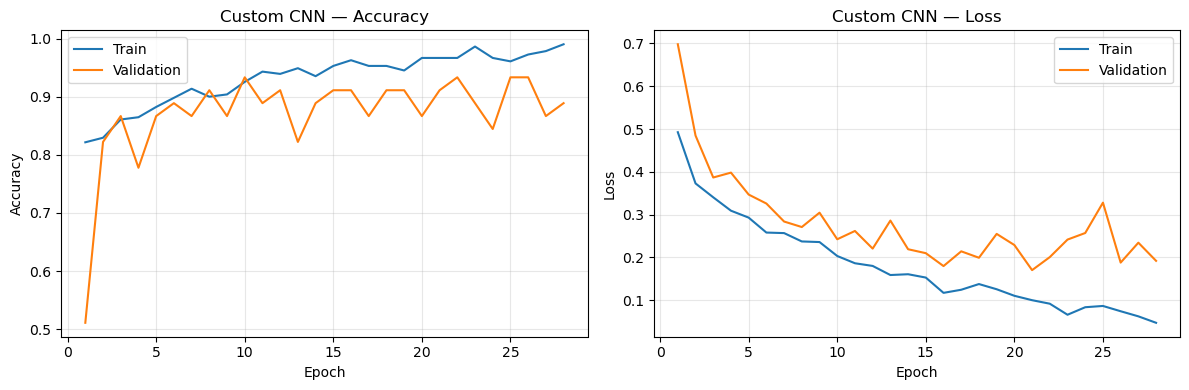

Saved: D:\Spinach_Leaf_Classification\results\custom_cnn\training_curves.png
Cell 10 complete.


In [13]:
def plot_history(history, model_name, save_dir):

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    ep = range(1, len(history["train_acc"]) + 1)

    axes[0].plot(ep, history["train_acc"], label="Train")
    axes[0].plot(ep, history["val_acc"],   label="Validation")
    axes[0].set_title(f"{model_name} — Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(ep, history["train_loss"], label="Train")
    axes[1].plot(ep, history["val_loss"],   label="Validation")
    axes[1].set_title(f"{model_name} — Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    save_path = save_dir / "training_curves.png"
    plt.savefig(save_path, dpi=120)
    plt.show()
    print("Saved:", save_path)


# Load history from CNN_RESULTS folder
history_path = CNN_RESULTS / "history.json"

if history_path.exists():
    with open(history_path) as f:
        history = json.load(f)
    plot_history(history, "Custom CNN", CNN_RESULTS)
else:
    print("History file not found:", history_path)
    print("Run Cell 8 first to train the model.")

print("Cell 10 complete.")

## Cell 11 — Evaluate on Test Set
Tests Custom CNN on unseen images. Saves confusion matrix to `results/custom_cnn/`.


MODEL: Custom CNN
Test images  : 45
Test loss    : 0.1473
Test accuracy: 95.56%

Classification Report:
              precision    recall  f1-score   support

         Big       0.92      1.00      0.96        23
       Small       1.00      0.91      0.95        22

    accuracy                           0.96        45
   macro avg       0.96      0.95      0.96        45
weighted avg       0.96      0.96      0.96        45



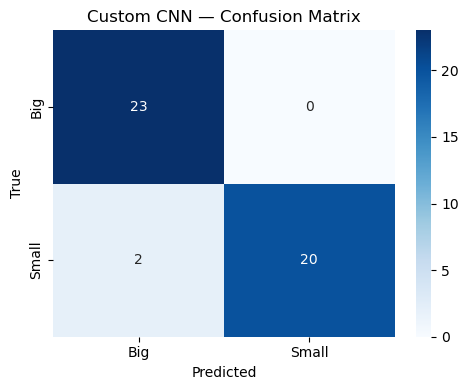

Confusion matrix saved: D:\Spinach_Leaf_Classification\results\custom_cnn\confusion_matrix.png
Cell 11 complete.


In [14]:
def evaluate_model(model, test_loader, model_name, class_indices, criterion, save_dir):

    model.eval()
    all_preds  = []
    all_labels = []
    total_loss = 0.0
    total_imgs = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images  = images.to(DEVICE)
            labels  = labels.to(DEVICE)
            outputs = model(images)
            loss    = criterion(outputs, labels.float().view(-1, 1))
            probs   = torch.sigmoid(outputs).view(-1)
            preds   = (probs >= 0.5).long()

            total_loss += loss.item() * labels.size(0)
            total_imgs += labels.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    test_loss = total_loss / total_imgs
    test_acc  = accuracy_score(all_labels, all_preds)

    idx_to_class = {v: k for k, v in class_indices.items()}
    class_names  = [idx_to_class[i] for i in range(len(class_indices))]
    pred_names   = [idx_to_class[p] for p in all_preds]
    true_names   = [idx_to_class[t] for t in all_labels]

    print("\n" + "=" * 55)
    print("MODEL:", model_name)
    print("=" * 55)
    print(f"Test images  : {total_imgs}")
    print(f"Test loss    : {test_loss:.4f}")
    print(f"Test accuracy: {test_acc*100:.2f}%")
    print("\nClassification Report:")
    print(classification_report(true_names, pred_names,
                                 labels=class_names, target_names=class_names,
                                 zero_division=0))

    # Confusion matrix
    cm = confusion_matrix(true_names, pred_names, labels=class_names)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f"{model_name} — Confusion Matrix")
    plt.ylabel("True")
    plt.xlabel("Predicted")
    plt.tight_layout()
    save_path = save_dir / "confusion_matrix.png"
    plt.savefig(save_path, dpi=120)
    plt.show()
    print("Confusion matrix saved:", save_path)

    return {"model": model_name, "test_loss": test_loss, "test_accuracy": test_acc}


# Evaluate Custom CNN — all results saved to CNN_RESULTS folder
results = evaluate_model(
    model         = model,
    test_loader   = test_loader,
    model_name    = "Custom CNN",
    class_indices = class_indices,
    criterion     = criterion,
    save_dir      = CNN_RESULTS
)

print("Cell 11 complete.")